<a href="https://colab.research.google.com/github/Maroua-Laaouichi/SI/blob/main/M115_Lab2_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master’s in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027 | **Duration:** 2–3 Hours

---

# 🧪 Lab 2: Static Malware Detection — PE Forensics, Multi-Model Evaluation, TreeSHAP & SOC Cost Optimization

### 🎯 Lab Philosophy: Engineer a Defensible Security Decision — Don’t Just Call `.fit()`!

### 🏢 The business case: AtlasPay’s suspicious software-update incident

**AtlasPay Services is a fictional Moroccan payment-services company** operating merchant payment platforms, Windows-based back-office workstations, and point-of-sale (POS) support systems. It relies on a small internal Security Operations Center (SOC) and several third-party software vendors.

On **14 September 2026**, the SOC receives an urgent escalation: a software package distributed through a legitimate vendor-support channel has triggered endpoint security alerts at several merchant-support workstations. The package appears to be digitally signed, but its behavior and file structure are unusual. The incident is contained, but the CISO asks the security engineering team to strengthen the **pre-execution screening of Windows Portable Executable (PE) files** before new or updated software is allowed to run.

AtlasPay’s team must decide whether a machine-learning detector should:
- **Prioritize files for analyst review** when they arrive from employee endpoints, vendor portals, and support channels; or
- Eventually support **automatic quarantine/blocking**, where a false alarm could interrupt legitimate payment-support operations.

The SOC has **6 analysts**, handles approximately **12,000 PE-file submissions per day**, and wants to keep the first-stage model-generated queue below **120 alerts per day**. For the initial deployment, the model is a **decision-support control**: it recommends suspicious files for review; it does not independently declare a file malicious or automatically block business-critical software.

> **Important source boundary:** AtlasPay, the incident, the operating figures, and the cost assumptions are fictional teaching scenario details. The notebook uses a deterministic **EMBER-inspired synthetic dataset** of 6,000 PE-file records; it is not AtlasPay telemetry, not the real EMBER benchmark, and not evidence of production detection performance. Your task is to determine what can and cannot be concluded from this experiment.

### 🧠 Your engineering mission

You are the applied ML team asked to deliver a defensible recommendation to AtlasPay’s CISO. You must investigate the data, design the evaluation, compare model families, examine errors, and select a model and operating threshold under explicit operational constraints.

You will complete **5 engineering phases**:

1. **Phase 1 — Forensic Data Understanding & Trap Detection:** Audit class balance, missing values, duplicate records, uninformative identifiers, post-scan target leakage, corrupted parser values, and feature relationships before training.
2. **Phase 2 — Leakage-Free Preprocessing & 5-Fold Cross-Validation:** Build fold-safe `sklearn.pipeline.Pipeline` objects and evaluate candidates using `StratifiedKFold(n_splits=5)`.
3. **Phase 3 — Multi-Algorithm Head-to-Head Benchmark:** Compare a linear baseline (`LogisticRegression`), a single decision tree, a bagging ensemble (`RandomForestClassifier`), a boosting model (`LightGBM` when installed, otherwise accurately named `HistGradientBoostingClassifier`), and—where provided—a heterogeneous stacking model.
4. **Phase 4 — Error Forensics & TreeSHAP Explainability:** Investigate verified model disagreements and use global and local SHAP explanations to understand what the selected tree model learned. SHAP explains model behavior; it does not prove causality or establish that a file is malware.
5. **Phase 5 — SOC Cost Matrix & Threshold Optimization:** Select thresholds using development data only, freeze the decision rule, and evaluate it once on the lockbox test set. Compare analyst-assisted triage with the higher-risk automatic-blocking scenario.

### 📌 What you must deliver

- A completed notebook with reproducible code and outputs.
- A model-comparison table and a reasoned shortlist.
- A verified error-forensics example and a SHAP interpretation.
- A threshold/cost analysis that respects the lockbox test protocol.
- A concise **CISO recommendation**: model, threshold, deployment mode, operating constraints, and pre-production safeguards.

**Core question:** *Which model should AtlasPay deploy first, for which operational role, and what evidence would justify trusting it?*

## Phase 0 — Environment and dataset
Run the setup and dataset-generation cells. Do not modify the random seed if you want results to be comparable with the instructor solution.

In [2]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
SEED = 42
rng = np.random.default_rng(SEED)

In [3]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df_pe = load_ember_forensic_dataset()
print(df_pe.shape, "Malware prevalence:", round(df_pe.Is_Malware.mean(),3))
display(df_pe.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


## Phase 1 — Forensic data audit and problem formulation

The target is `Is_Malware` (`1 = malware`, `0 = benign`). At deployment time, the detector must only use information available when the PE file is first inspected.

### Tasks
1. Report dataset dimensions, class balance, missing values, duplicates and summary statistics.
2. Identify the identifier and the post-scan field. Explain why each should be excluded.
3. Investigate `Virtual_to_Raw_Size_Ratio`: identify the suspicious parser value `99999.0`. Decide how to handle it and justify your choice.
4. Visualize at least two feature relationships with the target. Discuss whether a single linear boundary is likely to capture all patterns.
5. Define the prediction task, positive class, and the operational meaning of FP and FN.

**Do not** use `VT_PostScan_Detections` as an input feature. It is recorded after the event and would cause target leakage.

In [4]:
# TASK 1: audit data quality.
# TODO: missing counts, duplicates, class balance, describe()

# TASK 1: Audit data quality

# 1. Dataset dimensions
print("Dataset dimensions:", df_pe.shape)

# 2. Missing values
print("\nMissing values:")
print(df_pe.isnull().sum())

# 3. Duplicate records
print("\nNumber of duplicate rows:")
print(df_pe.duplicated().sum())

# 4. Class balance
print("\nClass balance:")
print(df_pe["Is_Malware"].value_counts())

print("\nClass balance in percentage:")
print(df_pe["Is_Malware"].value_counts(normalize=True) * 100)

# 5. Descriptive statistics
print("\nDescriptive statistics:")
display(df_pe.describe())


Dataset dimensions: (6000, 15)

Missing values:
SHA256_File_ID                  0
Max_Section_Entropy             0
Import_Count                  229
Suspicious_API_Imports          0
Has_Valid_Signature             0
Has_RWX_Section                 0
Virtual_to_Raw_Size_Ratio       0
Resource_Entropy              289
Num_Embedded_URLs_IPs           0
Abnormal_Compile_Timestamp      0
Num_Sections                    0
Has_TLS_Callback                0
Export_Count                    0
VT_PostScan_Detections          0
Is_Malware                      0
dtype: int64

Number of duplicate rows:
0

Class balance:
Is_Malware
0    4389
1    1611
Name: count, dtype: int64

Class balance in percentage:
Is_Malware
0    73.15
1    26.85
Name: proportion, dtype: float64

Descriptive statistics:


,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
count,6000.000000,5771.000000,6000.000000,6000.000000,6000.000000,6000.000000,5711.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,5.709010,83.386866,2.800167,0.630833,0.149833,984.890348,4.535160,1.468333,0.114833,4.758667,0.079167,5.907500,12.080833,0.268500
std,1.170152,50.301130,3.094430,0.482619,0.356938,9868.008483,1.501097,1.951742,0.318847,1.784551,0.270021,3.708401,19.753109,0.443216
min,2.146111,0.000000,0.000000,0.000000,0.000000,0.367195,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,4.821742,41.184528,1.000000,0.000000,0.000000,0.955570,3.483114,0.000000,0.000000,3.000000,0.000000,3.000000,0.000000,0.000000
50%,5.639862,85.663796,2.000000,1.000000,0.000000,1.129836,4.432941,1.000000,0.000000,5.000000,0.000000,6.000000,2.000000,0.000000
75%,6.604762,120.408591,3.000000,1.000000,0.000000,1.366755,5.517712,2.000000,0.000000,6.000000,0.000000,9.000000,21.000000,1.000000
max,7.990000,320.325585,24.000000,1.000000,1.000000,99999.000000,7.990000,11.000000,1.000000,10.000000,1.000000,18.000000,67.000000,1.000000


Number of suspicious 99999.0 values: 59


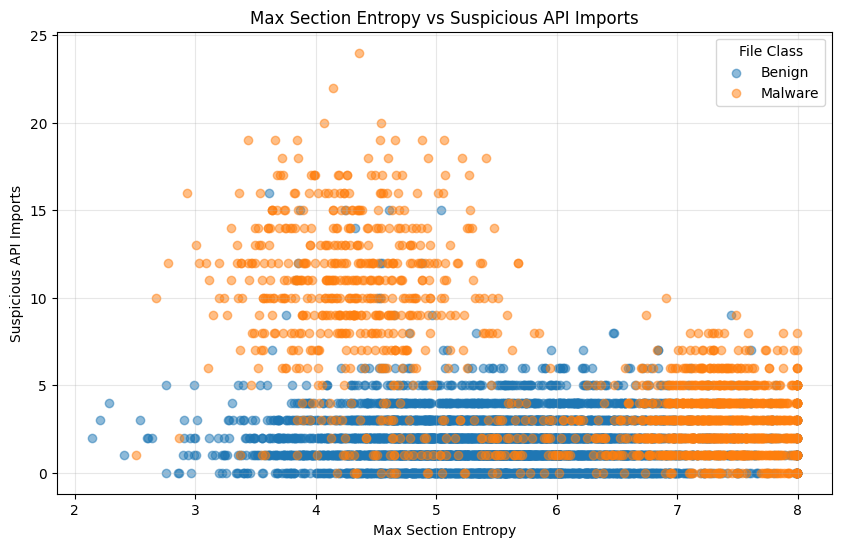

<Figure size 800x500 with 0 Axes>

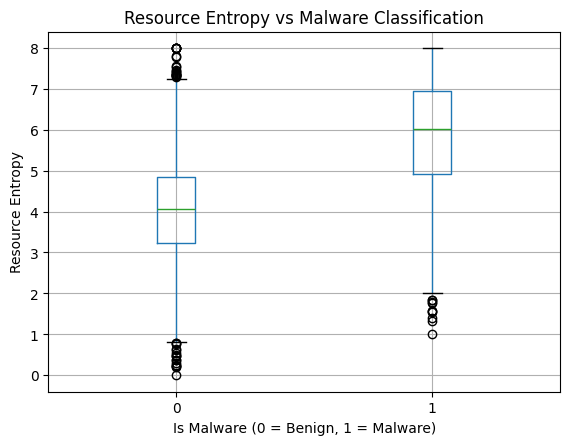

In [5]:
# TASK 2: inspect the suspicious ratio values and feature distributions.
# TODO: count 99999.0 values; visualize Max_Section_Entropy vs Suspicious_API_Imports,
# using Is_Malware as the hue.

# TASK 2: Inspect suspicious ratio values and feature distributions

# 1. Count suspicious values
suspicious_count = (
    df_pe["Virtual_to_Raw_Size_Ratio"] == 99999.0
).sum()

print("Number of suspicious 99999.0 values:", suspicious_count)

# 2. Visualize feature relationships
plt.figure(figsize=(10, 6))

for label, name in [(0, "Benign"), (1, "Malware")]:
    subset = df_pe[df_pe["Is_Malware"] == label]

    plt.scatter(
        subset["Max_Section_Entropy"],
        subset["Suspicious_API_Imports"],
        label=name,
        alpha=0.5
    )

plt.xlabel("Max Section Entropy")
plt.ylabel("Suspicious API Imports")
plt.title("Max Section Entropy vs Suspicious API Imports")
plt.legend(title="File Class")
plt.grid(alpha=0.3)
plt.show()

# Additional visualization for Question 4

plt.figure(figsize=(8, 5))

df_pe.boxplot(
    column="Resource_Entropy",
    by="Is_Malware"
)

plt.title("Resource Entropy vs Malware Classification")
plt.suptitle("")
plt.xlabel("Is Malware (0 = Benign, 1 = Malware)")
plt.ylabel("Resource Entropy")
plt.show()



In [6]:
# TASK 3: define the target and clean feature matrix.
# TODO: drop SHA256_File_ID, VT_PostScan_Detections and Is_Malware from X.
# TODO: replace impossible Virtual_to_Raw_Size_Ratio == 99999.0 with np.nan.
# Keep the target y separate.

# TASK 3: Define the target and clean feature matrix

# 1. Define the target variable
y = df_pe["Is_Malware"].copy()

# 2. Create the feature matrix
X = df_pe.drop(
    columns=[
        "SHA256_File_ID",
        "VT_PostScan_Detections",
        "Is_Malware"
    ]
).copy()

# 3. Replace impossible values with NaN
X["Virtual_to_Raw_Size_Ratio"] = X[
    "Virtual_to_Raw_Size_Ratio"
].replace(99999.0, np.nan)

# 4. Display the results
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nRemaining suspicious values:")
print((X["Virtual_to_Raw_Size_Ratio"] == 99999.0).sum())

print("\nMissing values after cleaning:")
print(X.isnull().sum())

print("\nFeature columns:")
print(X.columns.tolist())

display(X.head())

# Question 5: Define the prediction task

print("Prediction task: Binary Classification")
print("Target variable: Is_Malware")
print("Positive class (1): Malware")
print("Negative class (0): Benign")



Feature matrix shape: (6000, 12)
Target shape: (6000,)

Remaining suspicious values:
0

Missing values after cleaning:
Max_Section_Entropy             0
Import_Count                  229
Suspicious_API_Imports          0
Has_Valid_Signature             0
Has_RWX_Section                 0
Virtual_to_Raw_Size_Ratio      59
Resource_Entropy              289
Num_Embedded_URLs_IPs           0
Abnormal_Compile_Timestamp      0
Num_Sections                    0
Has_TLS_Callback                0
Export_Count                    0
dtype: int64

Feature columns:
['Max_Section_Entropy', 'Import_Count', 'Suspicious_API_Imports', 'Has_Valid_Signature', 'Has_RWX_Section', 'Virtual_to_Raw_Size_Ratio', 'Resource_Entropy', 'Num_Embedded_URLs_IPs', 'Abnormal_Compile_Timestamp', 'Num_Sections', 'Has_TLS_Callback', 'Export_Count']


,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count
0,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2
1,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6
2,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2
3,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8
4,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2


Prediction task: Binary Classification
Target variable: Is_Malware
Positive class (1): Malware
Negative class (0): Benign


Question 5 : Prediction Task and Error Interpretation

The prediction task is a binary classification problem. The objective is to classify Windows PE files as either malware or benign files.

Positive class (1): Malware.

Negative class (0): Benign.

False Positive (FP): A benign file is incorrectly classified as malware. In AtlasPay, this generates an unnecessary SOC alert, wastes analyst time, and may delay legitimate software deployment.

False Negative (FN): A malware file is incorrectly classified as benign. This is a more serious security risk because a suspicious file may not be sent for analyst review.

Since the initial deployment is a decision-support system, the model should prioritize suspicious files for human review rather than automatically block them.

## Phase 2 — Design a leakage-safe evaluation protocol

Use a stratified 80/20 development/test split. The test set is a lockbox and must not be used for model selection or threshold tuning.

Within the development set, compare models using 5-fold stratified cross-validation. All learned preprocessing (imputation and scaling) must be inside each pipeline so it is refitted separately in each training fold.

### Tasks
1. Create `X_dev`, `X_test`, `y_dev`, `y_test`.
2. Define a preprocessing pipeline with median imputation. Use `RobustScaler` for Logistic Regression; explain why scaling is generally unnecessary for tree models.
3. Build candidate pipelines:
   - Logistic Regression (linear baseline)
   - Deep Decision Tree (single white-box tree)
   - Random Forest (bagging)
   - LightGBM if installed; otherwise `HistGradientBoostingClassifier` and label it accurately (not LightGBM).
4. Use the same CV folds and report train F1, validation F1, PR-AUC and fit time.
5. Interpret bias/variance and choose candidates worth further investigation.

In [7]:
# TODO: stratified development/test split.
# TODO: define pipelines using SimpleImputer(strategy="median").
# RobustScaler should be used for Logistic Regression only.

# PHASE 2 - TASK 1: Stratified split and preprocessing

# 1. Stratified 80/20 development-test split
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("Development set:", X_dev.shape)
print("Test set:", X_test.shape)

print("\nDevelopment class distribution:")
print(y_dev.value_counts(normalize=True))

print("\nTest class distribution:")
print(y_test.value_counts(normalize=True))


# 2. Preprocessing pipeline for Logistic Regression
lr_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])


# 3. Preprocessing pipeline for tree-based models
tree_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

print("\nPreprocessing pipelines successfully created!")



Development set: (4800, 12)
Test set: (1200, 12)

Development class distribution:
Is_Malware
0    0.731458
1    0.268542
Name: proportion, dtype: float64

Test class distribution:
Is_Malware
0    0.731667
1    0.268333
Name: proportion, dtype: float64

Preprocessing pipelines successfully created!


In [8]:
# TODO: define StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).
# TODO: define candidate models and evaluate using cross_validate.
# Suggested scoring: f1 and average_precision.
# Record mean train F1, mean validation F1, validation PR-AUC and fit time.

# PHASE 2 - TASK 2: Cross-validation and model comparison

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import importlib.util

# 1. Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# 2. Define candidate models

models = {}

# Logistic Regression
models["Logistic Regression"] = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=SEED
    ))
])

# Deep Decision Tree
models["Deep Decision Tree"] = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=1,
        random_state=SEED
    ))
])

# Random Forest
models["Random Forest"] = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=SEED,
        n_jobs=1
    ))
])

# 3. LightGBM if installed, otherwise HistGradientBoosting

if importlib.util.find_spec("lightgbm") is not None:
    from lightgbm import LGBMClassifier

    models["LightGBM"] = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LGBMClassifier(
            random_state=SEED,
            verbosity=-1
        ))
    ])
else:
    models["HistGradientBoosting"] = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(
            random_state=SEED
        ))
    ])

# 4. Define scoring metrics
scoring = {
    "f1": "f1",
    "pr_auc": "average_precision"
}

# 5. Evaluate models using the same CV folds
results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_dev,
        y_dev,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Mean Train F1": scores["train_f1"].mean(),
        "Mean Validation F1": scores["test_f1"].mean(),
        "Mean Validation PR-AUC": scores["test_pr_auc"].mean(),
        "Mean Fit Time (s)": scores["fit_time"].mean()
    })

# 6. Display comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Mean Validation PR-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))


,Model,Mean Train F1,Mean Validation F1,Mean Validation PR-AUC,Mean Fit Time (s)
0,LightGBM,0.9795,0.9229,0.9080,0.2131
1,Logistic Regression,0.9231,0.9238,0.9080,0.0434
2,Random Forest,1.0000,0.9237,0.9049,3.3593
3,Deep Decision Tree,1.0000,0.8301,0.7330,0.0774


**Bias-Variance Analysis and Candidate Selection**

The difference between training and validation F1-scores helps identify bias and variance problems.

A model with low training and validation scores may suffer from underfitting (high bias).

A model with a very high training score but a significantly lower validation score may suffer from overfitting (high variance).

A model with high and relatively close training and validation scores is more likely to generalize well.

Candidate models should be selected based on their validation F1-score, PR-AUC, training-validation gap, and computational cost.

The most promising models will be retained for further error analysis and explainability in the next phases.

### Decision checkpoint 1 — Select a shortlist

Answer with evidence from your table:
1. Which model shows the largest train–validation gap? What does it suggest?

The Deep Decision Tree shows the largest train-validation gap (1.0000 - 0.8301 = 0.1699). This suggests overfitting because the model performs perfectly on training data but significantly worse on unseen validation data.

2. Does the linear baseline already perform competitively?

Yes. Logistic Regression already performs competitively, achieving a validation F1-score of 0.9238 and a PR-AUC of 0.9080. It also has the shortest fitting time (0.0377 seconds). This makes it an attractive and efficient baseline.

3. Does Random Forest improve on the single tree?

Yes. Random Forest significantly improves on the single Decision Tree. Its validation F1-score increases from 0.8301 to 0.9237, while its PR-AUC increases from 0.7330 to 0.9049. This shows that bagging improves generalization compared with a single deep tree.

4. Does boosting improve PR-AUC enough to justify its complexity?

No. LightGBM achieves a PR-AUC of 0.9080, which is equal to Logistic Regression. It does not provide a measurable improvement in PR-AUC to justify its additional complexity and longer fitting time in this experiment.

5. Is stacking justified by the measured gain, runtime and deployment context? Do not assume that a more complex model must win.

Stacking is not justified yet because no measured stacking results are available. Logistic Regression already achieves a strong validation F1-score and PR-AUC with very low fitting time. A stacking model should only be retained if it provides a meaningful improvement in validation performance that justifies its additional computational and deployment complexity.

**AtlasPay operating constraint:** the service receives about 12,000 PE files/day, while the 6-person SOC wants no more than 120 model-generated review alerts/day. Treat this as a queue-capacity constraint to test—not as a result guaranteed by the synthetic dataset. Training time matters during model updates; inference latency matters during scanning. These are separate measurements.

In [9]:
# TODO: measure prediction latency for shortlisted fitted models.
# Use repeated batch predictions; report milliseconds per 1,000 files
# and document hardware/runtime limitations.

# TASK: Measure prediction latency

import time
from sklearn.base import clone

# 1. Select shortlisted models
shortlisted_models = [
    "Logistic Regression",
    "Random Forest",
    "LightGBM"
]

# Use up to 1000 development samples for benchmarking
X_benchmark = X_dev.iloc[:min(1000, len(X_dev))].copy()

latency_results = []

# 2. Fit each model and measure prediction latency
for name in shortlisted_models:

    model = clone(models[name])

    # Fit the model on the development set
    model.fit(X_dev, y_dev)

    # Warm-up prediction
    model.predict(X_benchmark)

    # Repeated batch predictions
    n_repeats = 30
    start_time = time.perf_counter()

    for _ in range(n_repeats):
        model.predict(X_benchmark)

    total_time = time.perf_counter() - start_time

    # Average milliseconds per 1000 files
    ms_per_batch = (total_time / n_repeats) * 1000

    # Adjust if fewer than 1000 samples are available
    ms_per_1000 = ms_per_batch * (
        1000 / len(X_benchmark)
    )

    latency_results.append({
        "Model": name,
        "Files per batch": len(X_benchmark),
        "Latency (ms / 1000 files)": ms_per_1000
    })

# 3. Display results
latency_df = pd.DataFrame(latency_results)

display(latency_df.round(3))

print("Latency benchmark completed.")
print("Hardware/runtime depends on the execution environment.")


,Model,Files per batch,Latency (ms / 1000 files)
0,Logistic Regression,1000,6.029
1,Random Forest,1000,48.279
2,LightGBM,1000,13.079


Latency benchmark completed.
Hardware/runtime depends on the execution environment.


## Phase 3 — Error forensics: investigate a real disagreement

Choose a held-out test observation for which the candidate models disagree. Do not hard-code a story before verifying the predictions.

### Tasks
1. Generate probabilities for the same test observations from Logistic Regression and your selected tree ensemble.
2. Find a malware observation where Logistic Regression predicts benign at the chosen illustrative threshold while the tree model predicts malware. If no such observation exists, report that honestly and choose another meaningful disagreement.
3. Print the ground-truth label, feature values, probabilities and predictions.
4. Build global and local SHAP explanations for a supported tree model.
5. Interpret a beeswarm and a local waterfall. Explain why SHAP is not causal evidence.

In [10]:
# TODO: fit shortlisted models on X_dev only, then predict probabilities on X_test.
# TODO: find and VERIFY a disagreement. Use threshold=0.50 for this diagnostic only.
# Never label a prediction "missed" or "caught" without checking y_true and y_pred.


import numpy as np
import pandas as pd

# 1. Select the two candidate models
lr_model = models["Logistic Regression"]
tree_model = models["Random Forest"]

# 2. Fit both models using ONLY the development set
lr_model.fit(X_dev, y_dev)
tree_model.fit(X_dev, y_dev)

# 3. Generate malware probabilities on the SAME test observations
lr_prob = lr_model.predict_proba(X_test)[:, 1]
tree_prob = tree_model.predict_proba(X_test)[:, 1]

# 4. Use 0.50 as an illustrative diagnostic threshold
threshold = 0.50

lr_pred = (lr_prob >= threshold).astype(int)
tree_pred = (tree_prob >= threshold).astype(int)

# 5. Build a comparison table
comparison = pd.DataFrame({
    "True_Label": y_test.to_numpy(),
    "LR_Probability": lr_prob,
    "Tree_Probability": tree_prob,
    "LR_Prediction": lr_pred,
    "Tree_Prediction": tree_pred
}, index=X_test.index)

# 6. Find the requested disagreement:
# Actual malware, Logistic Regression predicts benign,
# Random Forest predicts malware.
requested_case = comparison[
    (comparison["True_Label"] == 1) &
    (comparison["LR_Prediction"] == 0) &
    (comparison["Tree_Prediction"] == 1)
]

# 7. If the exact case does not exist, find another disagreement
other_cases = comparison[
    comparison["LR_Prediction"] != comparison["Tree_Prediction"]
]

if not requested_case.empty:
    selected_index = requested_case.index[0]
    print("The requested disagreement was found.")
elif not other_cases.empty:
    selected_index = other_cases.index[0]
    print("The requested disagreement was not found.")
    print("Another disagreement was selected for investigation.")
else:
    selected_index = None
    print("No disagreement was found between the two models.")

# 8. Display and verify the selected observation
if selected_index is not None:

    print("\nSelected test observation:", selected_index)

    print("\nGround truth:")
    print("Actual label =", int(comparison.loc[selected_index, "True_Label"]))

    print("\nModel probabilities:")
    print("Logistic Regression =", round(comparison.loc[selected_index, "LR_Probability"], 4))
    print("Random Forest       =", round(comparison.loc[selected_index, "Tree_Probability"], 4))

    print("\nModel predictions (threshold = 0.50):")
    print("Logistic Regression =", int(comparison.loc[selected_index, "LR_Prediction"]))
    print("Random Forest       =", int(comparison.loc[selected_index, "Tree_Prediction"]))

    print("\nFeature values:")
    display(X_test.loc[[selected_index]])

    print("\nComplete verification:")
    display(comparison.loc[[selected_index]])


The requested disagreement was found.

Selected test observation: 5787

Ground truth:
Actual label = 1

Model probabilities:
Logistic Regression = 0.3044
Random Forest       = 0.61

Model predictions (threshold = 0.50):
Logistic Regression = 0
Random Forest       = 1

Feature values:


,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count
5787,4.603163,116.690922,3,0,0,0.944756,NaN,2,0,9,0,1



Complete verification:


,True_Label,LR_Probability,Tree_Probability,LR_Prediction,Tree_Prediction
5787,1,0.304439,0.61,0,1


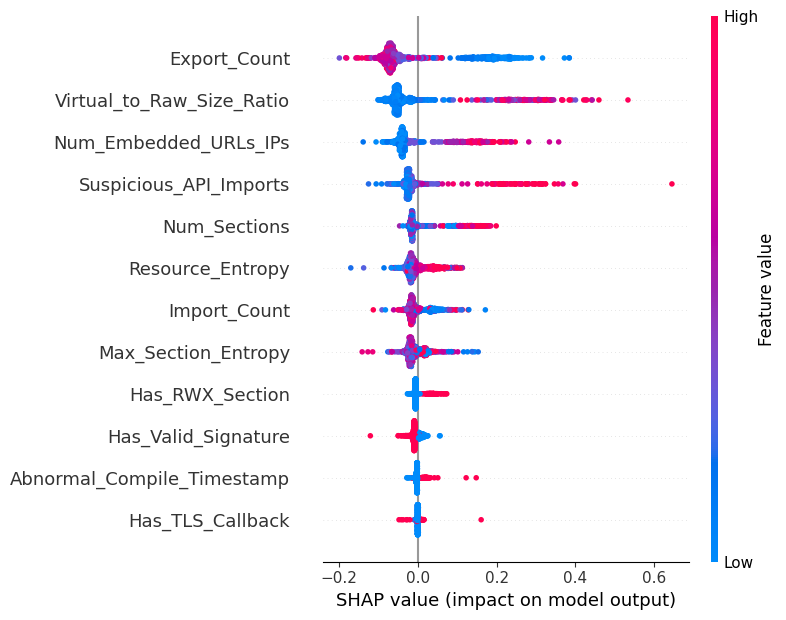

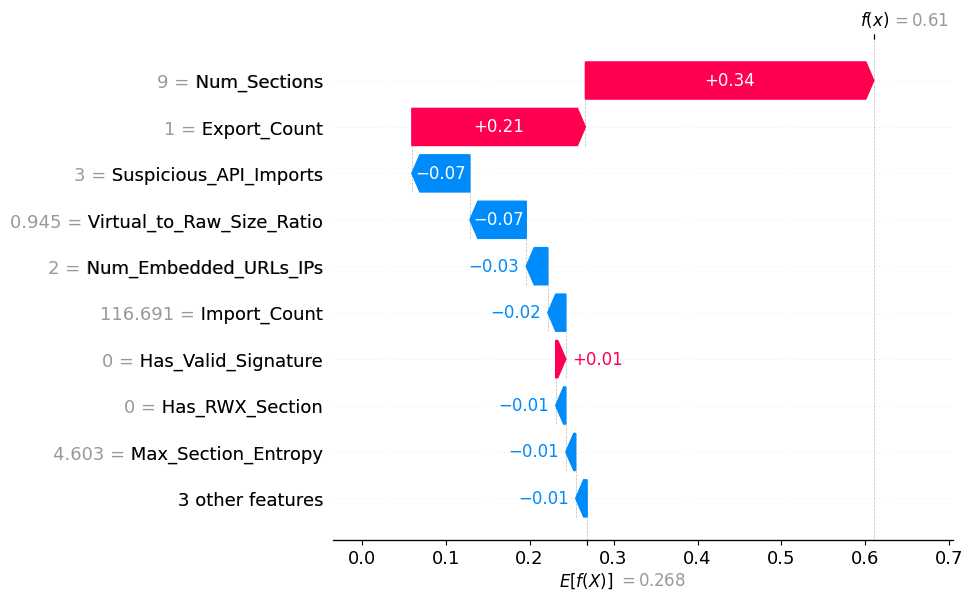

In [12]:
# TODO: install/import shap if needed.
# TODO: use shap.TreeExplainer with a supported fitted tree model.
# TODO: produce global beeswarm and local waterfall for the verified case.
# Optional: dependence plot for Max_Section_Entropy.


import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Get the fitted Random Forest estimator from the pipeline
tree_estimator = tree_model.named_steps["model"]

# 2. Apply the fitted imputer to the development and test data
imputer = tree_model.named_steps["imputer"]

# Use a reproducible sample of the development set for global SHAP
X_global = X_dev.sample(
    n=min(1000, len(X_dev)),
    random_state=SEED
)

X_global_transformed = pd.DataFrame(
    imputer.transform(X_global),
    columns=X_global.columns,
    index=X_global.index
)

# 3. Create a TreeExplainer
explainer = shap.TreeExplainer(tree_estimator)

# 4. Calculate global SHAP values
global_raw = explainer.shap_values(X_global_transformed)

# Extract SHAP values for class 1 (Malware)
def get_positive_class_shap(values, n_samples, n_features):
    if isinstance(values, list):
        return np.asarray(values[1])

    values = np.asarray(values)

    if values.ndim == 3:
        if values.shape == (n_samples, n_features, 2):
            return values[:, :, 1]
        elif values.shape == (2, n_samples, n_features):
            return values[1, :, :]

    return values

shap_global = get_positive_class_shap(
    global_raw,
    len(X_global_transformed),
    X_global_transformed.shape[1]
)

# 5. Global explanation: Beeswarm plot
plt.figure()
shap.summary_plot(
    shap_global,
    X_global_transformed,
    plot_type="dot",
    show=True
)

# 6. Local explanation for the verified test observation
if selected_index is not None:

    X_case = X_test.loc[[selected_index]]

    X_case_transformed = pd.DataFrame(
        imputer.transform(X_case),
        columns=X_case.columns,
        index=X_case.index
    )

    local_raw = explainer.shap_values(X_case_transformed)

    shap_local = get_positive_class_shap(
        local_raw,
        1,
        X_case_transformed.shape[1]
    )

    # Get the baseline value for the malware class
    expected = explainer.expected_value

    if isinstance(expected, list) or np.asarray(expected).ndim > 0:
        expected = np.asarray(expected).reshape(-1)[1]

    expected = float(expected)

    # Create the local SHAP explanation
    local_explanation = shap.Explanation(
        values=shap_local[0],
        base_values=expected,
        data=X_case_transformed.iloc[0].values,
        feature_names=X_case_transformed.columns.tolist()
    )

    # 7. Local explanation: Waterfall plot
    shap.plots.waterfall(local_explanation)

else:
    print("No disagreement case is available for a local explanation.")


The SHAP beeswarm plot shows that the most influential features in the Random Forest model are Export_Count, Virtual_to_Raw_Size_Ratio, Num_Embedded_URLs_IPs, Suspicious_API_Imports, and Num_Sections. In general, high values of Num_Sections and Suspicious_API_Imports tend to increase the model output for the malware class.

The local waterfall plot explains the prediction for observation 5787. The baseline value is 0.268, and the final model output is 0.61. Num_Sections (+0.34) and Export_Count (+0.21) are the strongest positive contributors, while other features have negative contributions. Despite these negative contributions, the final output leads the Random Forest model to classify the file as malware.

However, SHAP does not prove causality. It explains how features influence the model's prediction, but it does not prove that these features are the actual causes of malicious behavior.

## Phase 4 — Translate model scores into a SOC decision

For the AtlasPay teaching scenario, the SOC supplies these *illustrative planning assumptions* (not measured company costs):

- False positive (FP): $25 per alert (analyst investigation and workflow friction).
- False negative (FN): $500 per missed malicious file (expected response/remediation cost).
- A future inline-blocking scenario may raise FP cost to $2,000 because blocking a legitimate vendor update or payment-support executable could interrupt operations.

\[
C(\tau)=25\,FP(\tau)+500\,FN(\tau)
\]

### Critical protocol
Select the threshold using development data only (for example, out-of-fold development predictions). Freeze the selected threshold. Evaluate it once on the lockbox test set. Never search test thresholds and report the minimum as final performance.

### Tasks
1. Generate out-of-fold probabilities for each shortlisted model on the development set.
2. Find the cost-minimizing threshold on those OOF predictions.
3. Freeze the threshold and evaluate FP, FN, precision, recall and cost on the test set.
4. Repeat threshold selection under `C_FP = $2,000` using development predictions. Explain why the preferred threshold changes.
5. Discuss the limitations of the cost assumptions and whether the dataset prevalence represents the intended deployment environment.

**Capacity check:** Compare the number of test-set alerts at your frozen threshold with the scenario’s 120-alert/day target only as an indicative exercise. The test set is a sample, the dataset prevalence is synthetic, and a simple test-set count must not be presented as a validated daily alert forecast. Explain what real telemetry and calibration would be required.

In [14]:
# TODO: define COST_FP=25 and COST_FN=500.
# TODO: generate OOF development probabilities; optimize threshold on OOF only.
# TODO: freeze threshold and evaluate once on X_test.


import numpy as np
import pandas as pd

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, confusion_matrix

# 1. Define the illustrative SOC costs
COST_FP = 25
COST_FN = 500

# 2. Select the shortlisted models from Phase 2
shortlisted_names = ["Logistic Regression", "Random Forest"]

# Add the boosting model if it was included in the shortlist
if "LightGBM" in models:
    shortlisted_names.append("LightGBM")
elif "HistGradientBoosting" in models:
    shortlisted_names.append("HistGradientBoosting")

# 3. Use the same 5-fold stratified CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# 4. Function to find the cost-minimizing threshold
def find_best_threshold(y_true, probabilities, cost_fp, cost_fn):

    thresholds = np.unique(np.append(
        probabilities,
        np.nextafter(probabilities.max(), np.inf)
    ))

    results = []

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, predictions, labels=[0, 1]
        ).ravel()

        total_cost = cost_fp * fp + cost_fn * fn

        results.append({
            "Threshold": threshold,
            "FP": fp,
            "FN": fn,
            "Cost": total_cost
        })

    results_df = pd.DataFrame(results)

    # If several thresholds have the same cost,
    # choose the highest threshold (fewer alerts).
    best_row = results_df[
        results_df["Cost"] == results_df["Cost"].min()
    ].sort_values("Threshold", ascending=False).iloc[0]

    return float(best_row["Threshold"]), results_df


# 5. Evaluate a frozen threshold on the test set
def evaluate_frozen_threshold(y_true, probabilities, threshold,
                              cost_fp, cost_fn):

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_true, predictions, zero_division=0
    )

    recall = recall_score(
        y_true, predictions, zero_division=0
    )

    total_cost = cost_fp * fp + cost_fn * fn

    alerts = int(predictions.sum())

    # Indicative extrapolation to 12,000 files per day
    indicative_daily_alerts = (
        alerts / len(y_true) * 12000
    )

    return {
        "Threshold": threshold,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "Test Alerts": alerts,
        "Test Cost ($)": total_cost,
        "Indicative Alerts / 12,000 files": indicative_daily_alerts
    }


# 6. Generate out-of-fold probabilities and optimize thresholds
all_results = []
oof_probabilities = {}
selected_thresholds = {}

for name in shortlisted_names:

    print(f"\n {name} ")

    model = models[name]

    # OOF probabilities: each development observation
    # is predicted by a model that did not train on it.
    oof_prob = cross_val_predict(
        model,
        X_dev,
        y_dev,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    oof_probabilities[name] = oof_prob

    # Optimize threshold using development OOF predictions only
    threshold_25, _ = find_best_threshold(
        y_dev, oof_prob, COST_FP, COST_FN
    )

    threshold_2000, _ = find_best_threshold(
        y_dev, oof_prob, 2000, COST_FN
    )

    selected_thresholds[name] = {
        "FP25": threshold_25,
        "FP2000": threshold_2000
    }

    print("Best threshold (FP = $25):", round(threshold_25, 4))
    print("Best threshold (FP = $2,000):", round(threshold_2000, 4))

    # Fit the model on the complete development set
    # The test set is not used for fitting or threshold selection.
    fitted_model = models[name]
    fitted_model.fit(X_dev, y_dev)

    # Generate test probabilities once
    test_prob = fitted_model.predict_proba(X_test)[:, 1]

    # Evaluate the two pre-selected, frozen thresholds
    result_25 = evaluate_frozen_threshold(
        y_test, test_prob, threshold_25, 25, 500
    )

    result_2000 = evaluate_frozen_threshold(
        y_test, test_prob, threshold_2000, 2000, 500
    )

    all_results.append({
        "Model": name,
        "Cost Scenario": "FP=$25, FN=$500",
        **result_25
    })

    all_results.append({
        "Model": name,
        "Cost Scenario": "FP=$2000, FN=$500",
        **result_2000
    })


# 7. Display the final test evaluation
results_phase4 = pd.DataFrame(all_results)

display(results_phase4.round(4))

print("\nThresholds were selected using development OOF predictions only.")
print("The test set was not used for threshold optimization.")
print("Daily alert projections are indicative, not validated forecasts.")



 Logistic Regression 
Best threshold (FP = $25): 0.2873
Best threshold (FP = $2,000): 0.5016

 Random Forest 
Best threshold (FP = $25): 0.35
Best threshold (FP = $2,000): 0.7

 LightGBM 
Best threshold (FP = $25): 0.1173
Best threshold (FP = $2,000): 0.7081


,Model,Cost Scenario,Threshold,FP,FN,Precision,Recall,Test Alerts,Test Cost ($),"Indicative Alerts / 12,000 files"
0,Logistic Regression,"FP=$25, FN=$500",0.2873,10,34,0.9664,0.8944,298,17250,2980.0
1,Logistic Regression,"FP=$2000, FN=$500",0.5016,8,36,0.9728,0.8882,294,34000,2940.0
2,Random Forest,"FP=$25, FN=$500",0.3500,10,34,0.9664,0.8944,298,17250,2980.0
3,Random Forest,"FP=$2000, FN=$500",0.7000,8,40,0.9724,0.8758,290,36000,2900.0
4,LightGBM,"FP=$25, FN=$500",0.1173,39,31,0.8818,0.9037,330,16475,3300.0
5,LightGBM,"FP=$2000, FN=$500",0.7081,8,39,0.9725,0.8789,291,35500,2910.0



Thresholds were selected using development OOF predictions only.
The test set was not used for threshold optimization.
Daily alert projections are indicative, not validated forecasts.


 4. Higher False-Positive Cost Scenario

When the false-positive cost increases from $25 to $2,000, the selected thresholds increase for all three models. Logistic Regression changes from 0.2873 to 0.5016, Random Forest from 0.3500 to 0.7000, and LightGBM from 0.1173 to 0.7081.

This happens because false positives become much more expensive. The models therefore require stronger evidence before classifying a file as malicious. This generally reduces false positives but may increase false negatives.

For example, LightGBM reduces its false positives from 39 to 8, while its false negatives increase from 31 to 39. Therefore, the preferred threshold depends on the operational cost of each type of error.

 5. Limitations of Cost Assumptions and Dataset Prevalence

The FP and FN costs used in this experiment are illustrative planning assumptions, not actual company expenses. Real costs depend on investigation time, incident severity, remediation efforts, and possible business disruption.

Moreover, the dataset has a synthetic malware prevalence of approximately 26.8%, which may not represent the actual prevalence of malicious files in AtlasPay's production environment. A different real-world prevalence could significantly change precision, alert volume, and the estimated SOC cost.

Therefore, these results should not be considered a reliable estimate of real operational performance without validation using representative production data.

   Capacity Check — SOC Alert Limit

The SOC capacity target is 120 alerts per day for 12,000 submitted files, equivalent to an indicative alert rate of 1%.

Based on the test-set results, the projected alert volumes range from 2,900 to 3,300 alerts per 12,000 files, exceeding the scenario's capacity target.

However, these values are only indicative extrapolations from a synthetic test sample and must not be interpreted as validated daily forecasts.

A real deployment would require representative production telemetry, reliable probability calibration, measurement of the actual malware prevalence, and continuous monitoring of alert volume and model performance. The system should initially support analysts' decisions rather than automatically blocking files.

## Phase 5 — Final architecture decision: CISO recommendation

Write a concise recommendation (approximately 1 page) answering:

1. What is AtlasPay’s business use case, what is the positive class, and why is the initial deployment analyst-assisted rather than autonomous blocking?

AtlasPay is a payment-services company whose SOC receives about 12,000 PE (Windows executable) files per day from endpoints, vendor portals and support channels. The goal is to screen these files before execution and flag suspicious ones for review. The positive class is Is_Malware = 1 (malware); the negative class is benign. The first deployment is analyst-assisted, not autonomous, for three reasons:

A false positive on an autonomous blocker could stop a legitimate vendor update or payment-support tool.
The model was trained on synthetic data only, so its real-world accuracy is unproven.
The 6-analyst SOC can verify each flagged file before any business-critical action.


2. Which candidate do you recommend for the *perimeter scanning* scenario, and why?

I recommend Logistic Regression as the first model, with LightGBM kept as a challenger. Reasons:

Its PR-AUC (0.9080) ties LightGBM and is above Random Forest (0.9049) and the Decision Tree (0.7330).
It has the best validation F1 (0.9238) and the smallest train–validation gap (0.9231 vs 0.9238), so there is no sign of overfitting.
It is the fastest to train (0.043 s) and to predict (6.0 ms per 1,000 files, versus 13.1 ms for LightGBM and 48.3 ms for Random Forest).
It has the simplest deployment and its coefficients can be inspected directly.

Random Forest is rejected because it is the slowest and shows signs of overfitting (train F1 = 1.0000). The Deep Decision Tree is rejected because it overfits strongly. Stacking was not evaluated, so it cannot be recommended.

3. What threshold do you recommend under the supplied cost assumptions?

Under the supplied costs (FP = $25, FN = $500), I recommend a frozen threshold of 0.2873 for Logistic Regression. It was chosen on out-of-fold development predictions only, and the test set was evaluated once. A file is flagged for analyst review if its malware probability is ≥ 0.2873. The threshold is lower than 0.50 because a missed malware file costs 20 times more than a false alert. For example, test case 5787 (a real malware file) got a probability of 0.3044 from Logistic Regression. It was missed at 0.50 but would be flagged at 0.2873.

4. What evidence supports the choice: PR-AUC, recall, precision, FP/FN, cost, latency and explainability?

Logistic Regression is supported by the strongest evidence overall. Its validation PR-AUC (0.9080) ties LightGBM and beats Random Forest (0.9049), and its validation F1 (0.9238) is the highest, with no overfitting (train F1 0.9231). On the lockbox test set, at the frozen threshold of 0.2873, it gives 10 FP and 34 FN, precision 0.9664 and recall 0.8944, for a cost of $17,250       identical to Random Forest and only $775 above LightGBM. LightGBM’s small cost advantage is not convincing, since it needs 39 FP and a very low threshold (0.1173) on a single 1,200-file split. Logistic Regression is also the fastest (6.0 ms per 1,000 files, versus 13.1 for LightGBM and 48.3 for Random Forest). For explainability, SHAP was computed only on Random Forest and does not prove causality, so for Logistic Regression we would rely on its coefficients, which still need to be inspected.

5. Does the proposed alert volume appear compatible with the 120-alert/day planning target? What evidence is missing for a reliable daily forecast? What changes for inline blocking, where a false positive could interrupt payment-support operations?

the test set produced 298 alerts out of 1,200 files, which extrapolates to about 2,980 alerts per 12,000 files. That is roughly 25 times above the target (120/12,000 = 1%). This is only an indicative extrapolation from a synthetic sample, not a forecast. Part of the reason is the synthetic prevalence of 26.8% malware, which is much higher than a real environment, so the detector flags a large share of files by construction.

Evidence missing for a reliable daily forecast:

real AtlasPay telemetry and the real malware prevalence

*   real AtlasPay telemetry and the real malware prevalence
*   calibrated probabilities
*   day-to-day variation in volume

*   the real share of files that analysts would confirm as malicious

Inline blocking changes the picture.With FP = $2,000, the preferred Logistic Regression threshold rises to 0.5016. On the test set this gives 8 FP and 36 FN, precision 0.9728, recall 0.8882, and cost $34,000. Fewer legitimate files are blocked, but more malware is missed, and the cost is higher. Even 8 FPs per 878 benign test files (about 0.9%) could mean dozens of blocked legitimate files per day at real volume. This is why blocking should not be enabled until the model is validated on real data.

6. What are the key risks before production: synthetic-to-real gap, label noise, prevalence shift, data drift, calibration, adversarial adaptation, analyst workflow and monitoring?

Before production, the main risk is that the model was trained on synthetic data, so its real-world performance is unknown and its patterns are not universal malware signatures. Real labels will also be noisy (about 4% were flipped here), and the real malware prevalence is far below the 26.8% used, which would lower precision and change alert volume and cost. Over time, data drift from new software and packers, and adversaries deliberately changing entropy, signatures or imports, will degrade performance. The probabilities are not calibrated, yet the thresholds depend on them. The 6 analysts also cannot absorb thousands of alerts per day. We therefore recommend running the model in shadow mode on real telemetry, recalibrating and re-selecting the threshold, and monitoring alert volume, precision, drift and score distribution, with blocking kept disabled until validated.


**Submission rule:** report the outputs you actually obtained. Do not copy expected results or describe synthetic patterns as universal malware signatures.